In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stas

In [53]:
df = pd.read_parquet('../../data/processed/fide_players_active.parquet')
df_colombia = df[df['country'] == "COL"]
df_colombia.info()

<class 'pandas.DataFrame'>
Index: 5338 entries, 3127 to 436681
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   fideid        5338 non-null   string  
 1   name          5338 non-null   string  
 2   country       5338 non-null   category
 3   sex           5338 non-null   category
 4   title         5338 non-null   category
 5   w_title       5338 non-null   category
 6   o_title       5338 non-null   category
 7   rating        1685 non-null   Int64   
 8   rapid_rating  4012 non-null   Int64   
 9   blitz_rating  3466 non-null   Int64   
 10  birthday      5338 non-null   Int64   
 11  flag          5338 non-null   category
 12  es_activo     5338 non-null   bool    
 13  edad          5338 non-null   Int64   
 14  categoria     5338 non-null   category
dtypes: Int64(5), bool(1), category(7), string(2)
memory usage: 600.0 KB


In [54]:
df_colombia.describe().T

,count,mean,std,min,25%,50%,75%,max
rating,1685.0,1730.449258,205.812279,1400.0,1564.0,1709.0,1861.0,2493.0
rapid_rating,4012.0,1693.570538,175.748545,1401.0,1558.0,1672.0,1804.0,2513.0
blitz_rating,3466.0,1701.228217,184.53738,1401.0,1561.0,1679.0,1818.0,2558.0
birthday,5338.0,1993.321094,17.888772,1932.0,1982.0,1998.0,2008.0,2021.0
edad,5338.0,32.678906,17.888772,5.0,18.0,28.0,44.0,94.0


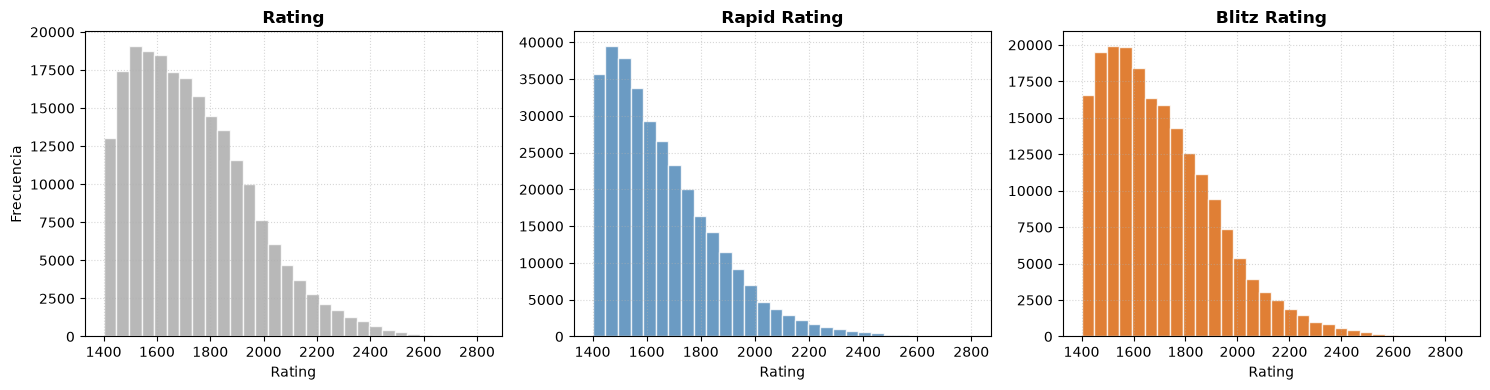

In [55]:
modalidades = [
    'rating',
    'rapid_rating',
    'blitz_rating',
]
colores = ["#A6A6A6", "steelblue", "#D95F02"]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), sharey=False)

for i, col in enumerate(modalidades): 
    ax[i].hist(df[col], bins=30, color=colores[i], edgecolor="white", alpha=0.8)
    ax[i].set_title(col.replace("_", " ").title(), fontsize=12, fontweight="bold")
    ax[i].set_xlabel("Rating")
    ax[i].set_ylabel("Frecuencia" if i == 0 else "")
    ax[i].grid(True, linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()
    


In [56]:
df_elos = df_colombia[['rating', 'rapid_rating', "blitz_rating"]]
df_elos.median().T

rating          1709.0
rapid_rating    1672.0
blitz_rating    1679.0
dtype: Float64

In [88]:

filtro =  df_elos.dropna()

print(df_elos.info())
print(' ')
print(filtro.info())

<class 'pandas.DataFrame'>
Index: 5338 entries, 3127 to 436681
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   rating        1685 non-null   Int64
 1   rapid_rating  4012 non-null   Int64
 2   blitz_rating  3466 non-null   Int64
dtypes: Int64(3)
memory usage: 182.5 KB
None
 
<class 'pandas.DataFrame'>
Index: 1283 entries, 4587 to 436681
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   rating        1283 non-null   Int64
 1   rapid_rating  1283 non-null   Int64
 2   blitz_rating  1283 non-null   Int64
dtypes: Int64(3)
memory usage: 43.9 KB
None


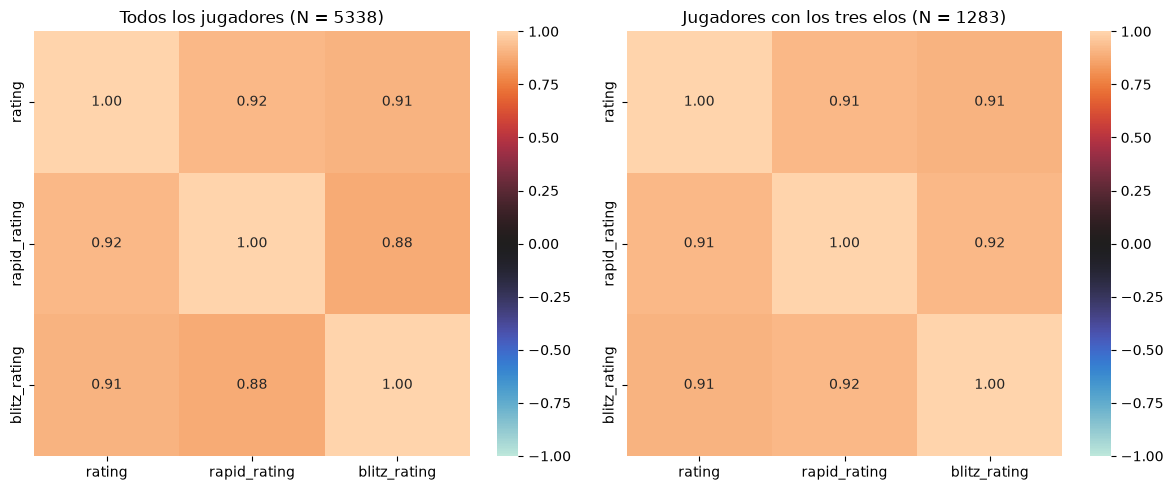

In [89]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.heatmap(
    df_elos.corr(),
    annot=True,
    cmap="icefire",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=ax[0],
)

ax[0].set_title(f"Todos los jugadores (N = {len(df_elos)})")

sns.heatmap(
    filtro.corr(),
    annot=True,
    cmap="icefire",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    ax=ax[1],
)
ax[1].set_title(f"Jugadores con los tres elos (N = {len(filtro)})")

fig.tight_layout()
plt.show()

**ESTUDIO**: Este grafico refleja una situacion muy comun en el analisis de correlaciones, cuando en las filas existe valores ausentes (Un jugador que no tiene elo Rating pero si el de blitz y rapida), ocurre que internamente al utilizar DataFrame.corr() pandas exluye el valor faltante, esto ocasiona un error en el resultado, haciendo que el calculo se vea afectado por la variacion en la cantidad de datos. Una forma de resolver esto es filtrar unicamente los jugadores que tienen un elo en las tres modalidades. 

In [90]:
df_conteo_jugadores = df_colombia.groupby('sex')[['rating','rapid_rating',"blitz_rating"]].count().T
df_conteo_jugadores['total'] = df_conteo_jugadores.sum(axis=1)
df_conteo_jugadores

sex,F,M,total
rating,258,1427,1685
rapid_rating,414,3598,4012
blitz_rating,409,3057,3466
